In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/questions.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2analysis_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/cid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_window_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/test.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/kc_routes_map.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/question_text.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv


In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import torch.nn as nn
import random
import json
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm   # thêm dòng này
import math
import json
import torch

# 1. Config

In [3]:
config = {
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv",
    "question_embed_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2content_emb.json",
    "concept_embed_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/cid2content_emb.json",
    "n_questions": 7652,
    "n_concepts": 865,
    "embed_dim_id": 128,
    "embed_dim_text": 768,
    "hidden_dim": 128,
    "proj_dim": 256,
    "top_k": 5,
    "batch_size": 128,
    "lr": 0.001,
    "num_epochs": 100,
    "patience": 10
}

# 2. DataLoading

In [4]:
import json
import torch

# ---------------------------------------------------------------------------
# Hàm nạp embedding pretrained CÓ chuẩn hoá — dùng thay cho load_embedding_json
# gốc trong Cell 5. Chuẩn hoá về unit-norm rồi nhân sqrt(dim) để giữ scale hợp lý
# cho attention (tương tự cách khởi tạo embedding thông thường trong Transformer).
# ---------------------------------------------------------------------------


def load_embedding_json_normalized(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    data = sorted(data.items(), key=lambda x: int(x[0]))
    embeddings = [embedding for _, embedding in data]
    tensor = torch.tensor(embeddings, dtype=torch.float32)

    norms = tensor.norm(dim=-1, keepdim=True).clamp(min=1e-8)
    dim = tensor.shape[-1]
    tensor = tensor / norms * math.sqrt(dim)
    return tensor


df_train_valid = pd.read_csv(config['data_train_valid_path'])
df_test = pd.read_csv(config['data_test_path'])
matrix_embed_question = load_embedding_json_normalized(config['question_embed_path'])
matrix_embed_concept = load_embedding_json_normalized(config['concept_embed_path'])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")
print(matrix_embed_question.shape)
print(matrix_embed_concept.shape)

Train: 33397
Test: 697697
torch.Size([7652, 768])
torch.Size([1175, 768])


# 3. Dataset & DataLoader

In [5]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class DemoDataset(Dataset):
    def __init__(self, df, fold=None, is_train=True):

        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold] 

        self.questions = [parse_seq(x) for x in df['questions']]
        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks= [parse_seq(x) for x in df['selectmasks']]

        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )
        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        q = torch.tensor(self.questions[i], dtype=torch.long).clamp(min=0)
        c = torch.tensor(self.concepts[i], dtype=torch.long).clamp(min=0)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)

        item = {
            "questions": q,
            "concepts": c,
            "responses": r,
            "selectmasks": m
        }
        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)
        return item

# 4. Model Definition

In [6]:
# import math
# import torch
# import torch.nn as nn
# import torch.nn.functional as F


# class Attention(nn.Module):
#     def __init__(self, dim):
#         super().__init__() 
#         self.dim = dim
#         self.W_q = nn.Linear(self.dim, self.dim)
#         self.W_k = nn.Linear(self.dim, self.dim)
#         self.W_v = nn.Linear(self.dim, self.dim)

#     def forward(self, q, k, v, mask=None):
#         Q = self.W_q(q)
#         K = self.W_k(k)
#         V = self.W_v(v)
#         scores = torch.matmul(Q, K.transpose(-2, -1))
#         scores = scores / math.sqrt(self.dim)
#         if mask is not None:
#             scores = scores.masked_fill(~mask, float('-inf'))
#         attention_weights = torch.softmax(scores, dim=-1)
#         attention_weights = torch.nan_to_num(attention_weights, nan=0.0)
#         output = torch.matmul(attention_weights, V)
#         return output, attention_weights


# class InteractionBlock(nn.Module):

#     def __init__(self, n_questions, n_concepts, hidden_dim, dim):
#         super().__init__()
#         self.n_questions = n_questions
#         self.n_concepts = n_concepts
#         self.hidden_dim = hidden_dim
#         self.dim = dim
#         self.question_embed = nn.Embedding(self.n_questions, 1)
#         self.concept_embed = nn.Embedding(self.n_concepts, self.dim)
#         self.concept_var_embed = nn.Embedding(self.n_concepts, self.dim)
#         self.interact_embed = nn.Embedding(2, self.dim)
#         self.q_attention = Attention(self.dim)
#         self.a_attention = Attention(self.dim)
#         self.q_a_attention = Attention(self.dim)
#         self.h0 = nn.Parameter(torch.zeros(1, 1, self.dim))

#         self.add_gate = nn.Sequential(
#             nn.Linear(self.dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.dim), nn.Sigmoid()
#         )
#         self.add_value = nn.Sequential(
#             nn.Linear(self.dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.dim)
#         )
#         self.remove_gate = nn.Sequential(
#             nn.Linear(self.dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.dim), nn.Sigmoid()
#         )
#         self.remove_value = nn.Sequential(
#             nn.Linear(self.dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.dim)
#         )

#     def forward(self, q, c, r):
#         B, T = q.shape
#         device = q.device

#         q_embed = self.question_embed(q)
#         c_embed = self.concept_embed(c)
#         c_var_embed = self.concept_var_embed(c)
#         r_embed = self.interact_embed(r)
#         q_embed = c_embed + q_embed * c_var_embed
#         a_embed = q_embed + r_embed

#         mask = torch.tril(torch.ones(T, T, device=device), diagonal=0).bool()
#         hq_embed, _ = self.q_attention(q_embed, q_embed, q_embed, mask)
#         ha_embed, _ = self.a_attention(a_embed, a_embed, a_embed, mask)

#         strict_mask = torch.tril(torch.ones(T, T, device=device), diagonal=-1).bool()
#         ha_embed, ha_weights = self.q_a_attention(hq_embed, hq_embed, ha_embed, strict_mask)

#         h = self.h0.expand(B, 1, self.dim)
#         hidden_states = []
#         for t in range(T):
#             q_t = q_embed[:, t, :]
#             ha_t = ha_embed[:, t, :]
#             h_t = h[:, 0, :]
#             z = torch.cat([h_t, q_t, ha_t], dim=-1)

#             add = self.add_gate(z) * self.add_value(z)
#             remove = self.remove_gate(z) * self.remove_value(z)
#             h_candidate = h_t + add - remove
#             hidden_states.append(h_candidate)
#             h = h_candidate.unsqueeze(1)

#         hidden_states = torch.stack(hidden_states, dim=1)
#         return hidden_states


# class ConceptGapScorer(nn.Module):
#     def __init__(self, c_embed_layer, dim=768, top_k=5):
#         super().__init__()
#         self.top_k = top_k
#         self.c_embed_layer = c_embed_layer
#         self.dim = dim
#         self.question_query = nn.Linear(self.dim, self.dim)
#         self.h_candidate_query = nn.Linear(self.dim, self.dim)
#         self.concept_key = nn.Linear(self.dim, self.dim)

#     def forward(self, q_embed, h_candidate):
#         # q_embed, h_candidate: (batch, dim) -- i.e. a SINGLE timestep's vectors.
#         concept_embed = self.c_embed_layer.weight
#         q_query = self.question_query(q_embed)
#         h_query = self.h_candidate_query(h_candidate)
#         concept_key = self.concept_key(concept_embed)
#         rank = torch.matmul(q_query, concept_key.T)
#         _, topk_idx = torch.topk(rank, k=self.top_k, dim=-1)
#         selected_key = concept_key[topk_idx]
#         attn_q = torch.bmm(q_query.unsqueeze(1), selected_key.transpose(1, 2)).squeeze(1)
#         attn_h = torch.bmm(h_query.unsqueeze(1), selected_key.transpose(1, 2)).squeeze(1)
#         attn_q = torch.softmax(attn_q, dim=-1)
#         attn_h = torch.softmax(attn_h, dim=-1)
#         score = attn_h - attn_q  # (batch, top_k)
#         return score


# class DifficultyProjector(nn.Module): 
#     def __init__(self, dim=768, hidden_dim=None, dropout=0.1):  
#         super().__init__()
#         hidden_dim = hidden_dim or dim
#         self.proj = nn.Sequential(
#             nn.Linear(dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
#             nn.Linear(hidden_dim, dim)
#         )

#     def forward(self, q_embed):
#         return self.proj(q_embed)


# class SematicTextBlock(nn.Module):
#     """Text-embedding-based encoder (pretrained question/concept text vectors)."""

#     def __init__(self, matrix_embed_question, matrix_embed_concept, hidden_dim,
#                  embed_dim, top_k=5):
#         super().__init__()
#         self.hidden_dim = hidden_dim
#         self.embed_dim = embed_dim 

#         self.q_embed_layer = nn.Embedding.from_pretrained(matrix_embed_question, freeze=True)
#         self.c_embed_layer = nn.Embedding.from_pretrained(matrix_embed_concept, freeze=True)
#         self.interact_embed = nn.Embedding(2, self.embed_dim)

#         self.q_attention = Attention(self.embed_dim)
#         self.a_attention = Attention(self.embed_dim)
#         self.q_a_attention = Attention(self.embed_dim)
#         self.h0 = nn.Parameter(torch.zeros(1, 1, self.embed_dim))

#         self.concept_gap_scorer = ConceptGapScorer(self.c_embed_layer, dim=self.embed_dim,
#                                                      top_k=top_k)
#         self.difficulty_projector = DifficultyProjector(dim=self.embed_dim)

#         self.add_gate = nn.Sequential(
#             nn.Linear(self.embed_dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.embed_dim), nn.Sigmoid()
#         )
#         self.add_value = nn.Sequential(
#             nn.Linear(self.embed_dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.embed_dim)
#         )
#         self.remove_gate = nn.Sequential(
#             nn.Linear(self.embed_dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.embed_dim), nn.Sigmoid()
#         )
#         self.remove_value = nn.Sequential(
#             nn.Linear(self.embed_dim * 3, self.hidden_dim), nn.ReLU(),
#             nn.Linear(self.hidden_dim, self.embed_dim)
#         )

#     def forward(self, q, r):
        
#         B, T = q.shape
#         device = q.device

#         q_embed = self.q_embed_layer(q)
#         r_embed = self.interact_embed(r)
#         a_embed = q_embed + r_embed

#         mask = torch.tril(torch.ones(T, T, device=device), diagonal=0).bool()
#         hq_embed, _ = self.q_attention(q_embed, q_embed, q_embed, mask)
#         ha_embed, _ = self.a_attention(a_embed, a_embed, a_embed, mask)

#         strict_mask = torch.tril(torch.ones(T, T, device=device), diagonal=-1).bool()
#         ha_embed, ha_weights = self.q_a_attention(hq_embed, hq_embed, ha_embed, strict_mask)

#         h = self.h0.expand(B, 1, self.embed_dim)
#         hidden_states, master_concepts, questions_difficult = [], [], []
#         for t in range(T):
#             q_t = q_embed[:, t, :]
#             ha_t = ha_embed[:, t, :]
#             h_t = h[:, 0, :]
#             z = torch.cat([h_t, q_t, ha_t], dim=-1)

#             add = self.add_gate(z) * self.add_value(z)
#             remove = self.remove_gate(z) * self.remove_value(z)
#             h_candidate = h_t + add - remove
#             hidden_states.append(h_candidate)
#             h = h_candidate.unsqueeze(1)

            
#             master_c = self.concept_gap_scorer(q_t, h_candidate)
#             master_concepts.append(master_c)
#             question_diff = self.difficulty_projector(q_t)
#             questions_difficult.append(question_diff)

#         hidden_states = torch.stack(hidden_states, dim=1)
#         master_concepts = torch.stack(master_concepts, dim=1)        # (B, T, top_k)
#         questions_difficult = torch.stack(questions_difficult, dim=1)  # (B, T, embed_dim)
#         return hidden_states, master_concepts, questions_difficult


# class TextFusionIdModel(nn.Module):
#     def __init__(self, n_questions, n_concepts, embed_dim_id, embed_dim_text,
#                  matrix_embed_question, matrix_embed_concept, hidden_dim, proj_dim, top_k):
#         super().__init__()
#         self.id_block = InteractionBlock(n_questions, n_concepts, hidden_dim, embed_dim_id)
#         self.text_block = SematicTextBlock(
#             matrix_embed_question, matrix_embed_concept, hidden_dim, embed_dim_text,
#             top_k=top_k
#         )
#         self.id_proj = nn.Linear(embed_dim_id, proj_dim)
#         self.text_proj = nn.Linear(embed_dim_text, proj_dim)

#         self.fusion_proj = nn.Linear(embed_dim_id + embed_dim_text, proj_dim)
#         self.out_proj = nn.Linear(proj_dim, 1)
#         self.out_master_c = nn.Linear(top_k, 1)
#         self.out_difficult_projector = nn.Linear(embed_dim_text, 1)

#     def forward(self, q, c, r):
#         h_id = self.id_block(q, c, r)
#         h_text, master_concepts, questions_difficult = self.text_block(q, r)
#         h = torch.cat([h_id, h_text], dim=-1)

#         alpha = torch.sigmoid(self.fusion_proj(h))
#         h_final = alpha * self.id_proj(h_id) + (1 - alpha) * self.text_proj(h_text)

#         out = (self.out_proj(h_final)
#                + self.out_master_c(master_concepts)
#                - self.out_difficult_projector(questions_difficult))
#         return out.squeeze(-1)


In [7]:
"""
model_v2.py — bản viết lại của khối Model Definition (Cell 9 trong notebook gốc)

Các thay đổi chính so với bản gốc, và LÝ DO:

1. GIẢM THỜI GIAN CHẠY:
   a) `concept_key` trong ConceptGapScorer được tính 1 LẦN DUY NHẤT mỗi forward
      (hoist ra ngoài vòng lặp theo t), thay vì tính lại y hệt ở cả 200 timestep.
   b) Gộp 4 MLP (add_gate, add_value, remove_gate, remove_value) — vốn là 4 mạng
      2 lớp riêng biệt dùng chung input z — thành 1 "thân chung" (shared trunk)
      + 4 "đầu" (heads) tuyến tính. Giảm từ ~8 phép Linear/ReLU tuần tự xuống còn
      ~5 phép mỗi timestep => giảm đáng kể số lần gọi kernel CUDA nhỏ lẻ, vốn là
      nguyên nhân chính khiến 1 epoch mất >8 phút (loop Python tuần tự qua ~200
      bước thời gian).
   c) Thêm cờ `use_amp`-friendly (không ép kiểu cứng), để bạn có thể bọc
      `torch.autocast()` ở training loop mà không phải sửa model.

2. GIẢM / ỔN ĐỊNH LOSS (chống nổ loss):
   a) Thêm LayerNorm ngay sau khi cộng gộp embedding (q_embed, a_embed) — đặc biệt
      quan trọng với SematicTextBlock vì pretrained text embedding (768-dim) có
      thể có scale rất lớn/không đồng đều, dễ làm attention score nổ.
   b) Thêm LayerNorm ngay sau bước cập nhật hồi quy `h_candidate = h_t + add - remove`.
      Đây là điểm quan trọng nhất: qua ~200 bước cộng dồn KHÔNG có chuẩn hoá, hidden
      state có thể tăng không kiểm soát (giống RNN không ổn định) => logits cực lớn
      => BCEWithLogitsLoss cực lớn ngay từ batch đầu. Thêm LayerNorm chặn đà tăng này.
   c) Thêm option chuẩn hoá embedding pretrained ngay sau khi load (xem hàm
      `load_embedding_json_normalized` ở cuối file) — nên dùng hàm này thay cho
      `load_embedding_json` gốc khi nạp qid2content_emb.json / cid2content_emb.json.

LƯU Ý: các thay đổi này KHÔNG đổi API bên ngoài — TextFusionIdModel vẫn nhận
(q, c, r) và trả về logits (B, T) như cũ, nên bạn chỉ cần thay thế Cell 9 bằng
file này, phần Train Loop / Dataset không cần sửa gì thêm.
"""

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ---------------------------------------------------------------------------
# Attention (giữ nguyên logic causal-mask — phần này vốn đã đúng)
# ---------------------------------------------------------------------------
class Attention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.W_q = nn.Linear(dim, dim)
        self.W_k = nn.Linear(dim, dim)
        self.W_v = nn.Linear(dim, dim)

    def forward(self, q, k, v, mask=None):
        Q = self.W_q(q)
        K = self.W_k(k)
        V = self.W_v(v)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.dim)
        if mask is not None:
            scores = scores.masked_fill(~mask, float('-inf'))
        attention_weights = torch.softmax(scores, dim=-1)
        attention_weights = torch.nan_to_num(attention_weights, nan=0.0)
        output = torch.matmul(attention_weights, V)
        return output, attention_weights


# ---------------------------------------------------------------------------
# Khối gate dùng chung cho cả InteractionBlock lẫn SematicTextBlock.
# Thay vì 4 Sequential riêng (add_gate, add_value, remove_gate, remove_value),
# dùng 1 trunk chung + 4 head tuyến tính => ít phép tính & ít lần launch kernel hơn,
# đồng thời có LayerNorm để chặn hidden state nổ qua nhiều timestep.
# ---------------------------------------------------------------------------
class RecurrentGateCell(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(dim * 3, hidden_dim), nn.ReLU())
        self.add_gate_head = nn.Linear(hidden_dim, dim)
        self.add_value_head = nn.Linear(hidden_dim, dim)
        self.remove_gate_head = nn.Linear(hidden_dim, dim)
        self.remove_value_head = nn.Linear(hidden_dim, dim)
        # LayerNorm sau cập nhật hồi quy — điểm mấu chốt chống nổ loss
        self.out_norm = nn.LayerNorm(dim)

    def forward(self, h_t, q_t, ha_t):
        z = torch.cat([h_t, q_t, ha_t], dim=-1)
        hidden = self.trunk(z)
        add = torch.sigmoid(self.add_gate_head(hidden)) * self.add_value_head(hidden)
        remove = torch.sigmoid(self.remove_gate_head(hidden)) * self.remove_value_head(hidden)
        h_candidate = h_t + add - remove
        return self.out_norm(h_candidate)


# ---------------------------------------------------------------------------
# InteractionBlock (nhánh ID)
# ---------------------------------------------------------------------------
class InteractionBlock(nn.Module):
    def __init__(self, n_questions, n_concepts, hidden_dim, dim):
        super().__init__()
        self.n_questions = n_questions
        self.n_concepts = n_concepts
        self.hidden_dim = hidden_dim
        self.dim = dim

        self.question_embed = nn.Embedding(n_questions, 1)
        self.concept_embed = nn.Embedding(n_concepts, dim)
        self.concept_var_embed = nn.Embedding(n_concepts, dim)
        self.interact_embed = nn.Embedding(2, dim)

        # LayerNorm ngay sau khi tạo embedding tổng hợp — ổn định scale đầu vào attention
        self.q_embed_norm = nn.LayerNorm(dim)
        self.a_embed_norm = nn.LayerNorm(dim)

        self.q_attention = Attention(dim)
        self.a_attention = Attention(dim)
        self.q_a_attention = Attention(dim)
        self.h0 = nn.Parameter(torch.zeros(1, 1, dim))

        self.gate_cell = RecurrentGateCell(dim, hidden_dim)

    def forward(self, q, c, r):
        B, T = q.shape
        device = q.device

        q_id_embed = self.question_embed(q)
        c_embed = self.concept_embed(c)
        c_var_embed = self.concept_var_embed(c)
        r_embed = self.interact_embed(r)

        q_embed = c_embed + q_id_embed * c_var_embed
        q_embed = self.q_embed_norm(q_embed)
        a_embed = self.a_embed_norm(q_embed + r_embed)

        mask = torch.tril(torch.ones(T, T, device=device), diagonal=0).bool()
        hq_embed, _ = self.q_attention(q_embed, q_embed, q_embed, mask)
        ha_embed, _ = self.a_attention(a_embed, a_embed, a_embed, mask)

        strict_mask = torch.tril(torch.ones(T, T, device=device), diagonal=-1).bool()
        ha_embed, _ = self.q_a_attention(hq_embed, hq_embed, ha_embed, strict_mask)

        h = self.h0.expand(B, 1, self.dim).squeeze(1)  # (B, dim)
        hidden_states = []
        for t in range(T):
            q_t = q_embed[:, t, :]
            ha_t = ha_embed[:, t, :]
            h = self.gate_cell(h, q_t, ha_t)
            hidden_states.append(h)

        return torch.stack(hidden_states, dim=1)


# ---------------------------------------------------------------------------
# ConceptGapScorer — concept_key giờ được tính bên ngoài (truyền vào forward)
# thay vì tự tính lại mỗi timestep.
# ---------------------------------------------------------------------------
class ConceptGapScorer(nn.Module):
    def __init__(self, dim=768, top_k=5):
        super().__init__()
        self.top_k = top_k
        self.dim = dim
        self.question_query = nn.Linear(dim, dim)
        self.h_candidate_query = nn.Linear(dim, dim)
        self.concept_key_proj = nn.Linear(dim, dim)

    def precompute_concept_key(self, concept_embed):
        """Gọi 1 LẦN mỗi forward (không phải mỗi timestep)."""
        return self.concept_key_proj(concept_embed)  # (n_concepts, dim)

    def forward(self, q_embed, h_candidate, concept_key):
        q_query = self.question_query(q_embed)
        h_query = self.h_candidate_query(h_candidate)
        rank = torch.matmul(q_query, concept_key.T)
        _, topk_idx = torch.topk(rank, k=self.top_k, dim=-1)
        selected_key = concept_key[topk_idx]
        attn_q = torch.bmm(q_query.unsqueeze(1), selected_key.transpose(1, 2)).squeeze(1)
        attn_h = torch.bmm(h_query.unsqueeze(1), selected_key.transpose(1, 2)).squeeze(1)
        attn_q = torch.softmax(attn_q, dim=-1)
        attn_h = torch.softmax(attn_h, dim=-1)
        return attn_h - attn_q  # (batch, top_k)


class PositiveLinear(nn.Module):
    """
    Linear layer với weight LUÔN DƯƠNG, dùng cho out_master_c.

    Ý tưởng: master_concepts (mastery gap = attn_h - attn_q) mang dấu có ý nghĩa —
    âm nghĩa là "hụt" ở concept đó. Muốn đảm bảo tính đơn điệu: gap càng âm thì
    đóng góp vào logit càng phải giảm (không bao giờ được phép ngược lại), nên
    weight nhân với gap bắt buộc phải dương.

    Cách làm: lưu 1 tham số thực `weight_raw` (có thể âm/dương tự do khi train
    bằng gradient descent), rồi ép dương bằng softplus(weight_raw) trước khi dùng.
    Softplus được chọn thay vì torch.abs() vì:
      - Mượt (smooth, khả vi mọi nơi) — abs() có đạo hàm không liên tục tại 0,
        có thể gây bất ổn khi weight dao động quanh 0 lúc train.
      - softplus(x) = log(1 + e^x) > 0 luôn luôn, và xấp xỉ x khi x lớn, xấp xỉ 0
        khi x rất âm — cho phép model "tắt" gần như hoàn toàn 1 concept nếu cần
        (weight -> 0) mà không bị chặn cứng ở 1 giá trị dương tối thiểu.
    """
    def __init__(self, in_features, out_features=1):
        super().__init__()
        self.weight_raw = nn.Parameter(torch.randn(out_features, in_features) * 0.01)
        self.bias = nn.Parameter(torch.zeros(out_features))

    def forward(self, x):
        positive_weight = F.softplus(self.weight_raw)
        return F.linear(x, positive_weight, self.bias)


class DifficultyProjector(nn.Module):
    def __init__(self, dim=768, hidden_dim=None, dropout=0.1):
        super().__init__()
        hidden_dim = hidden_dim or dim
        self.proj = nn.Sequential(
            nn.Linear(dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, dim)
        )

    def forward(self, q_embed):
        return self.proj(q_embed)


# ---------------------------------------------------------------------------
# SematicTextBlock (nhánh text pretrained)
# ---------------------------------------------------------------------------
class SematicTextBlock(nn.Module):
    def __init__(self, matrix_embed_question, matrix_embed_concept, hidden_dim,
                 embed_dim, top_k=5):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.embed_dim = embed_dim

        self.q_embed_layer = nn.Embedding.from_pretrained(matrix_embed_question, freeze=True)
        self.c_embed_layer = nn.Embedding.from_pretrained(matrix_embed_concept, freeze=True)
        self.interact_embed = nn.Embedding(2, embed_dim)

        # LayerNorm học được ngay sau embedding pretrained (frozen) — vì embedding
        # gốc có thể có scale rất khác nhau / rất lớn, đây là chỗ chặn đầu tiên.
        self.q_embed_norm = nn.LayerNorm(embed_dim)
        self.a_embed_norm = nn.LayerNorm(embed_dim)
        self.concept_embed_norm = nn.LayerNorm(embed_dim)

        self.q_attention = Attention(embed_dim)
        self.a_attention = Attention(embed_dim)
        self.q_a_attention = Attention(embed_dim)
        self.h0 = nn.Parameter(torch.zeros(1, 1, embed_dim))

        self.concept_gap_scorer = ConceptGapScorer(dim=embed_dim, top_k=top_k)
        self.difficulty_projector = DifficultyProjector(dim=embed_dim)

        self.gate_cell = RecurrentGateCell(embed_dim, hidden_dim)

    def forward(self, q, r):
        B, T = q.shape
        device = q.device

        q_embed = self.q_embed_norm(self.q_embed_layer(q))
        r_embed = self.interact_embed(r)
        a_embed = self.a_embed_norm(q_embed + r_embed)

        mask = torch.tril(torch.ones(T, T, device=device), diagonal=0).bool()
        hq_embed, _ = self.q_attention(q_embed, q_embed, q_embed, mask)
        ha_embed, _ = self.a_attention(a_embed, a_embed, a_embed, mask)

        strict_mask = torch.tril(torch.ones(T, T, device=device), diagonal=-1).bool()
        ha_embed, _ = self.q_a_attention(hq_embed, hq_embed, ha_embed, strict_mask)

        # concept_key tính 1 lần duy nhất ở đây, KHÔNG tính lại trong loop bên dưới
        concept_embed_normed = self.concept_embed_norm(self.c_embed_layer.weight)
        concept_key = self.concept_gap_scorer.precompute_concept_key(concept_embed_normed)

        h = self.h0.expand(B, 1, self.embed_dim).squeeze(1)
        hidden_states, master_concepts, questions_difficult = [], [], []
        for t in range(T):
            q_t = q_embed[:, t, :]
            ha_t = ha_embed[:, t, :]
            h = self.gate_cell(h, q_t, ha_t)
            hidden_states.append(h)

            master_c = self.concept_gap_scorer(q_t, h, concept_key)
            master_concepts.append(master_c)
            questions_difficult.append(self.difficulty_projector(q_t))

        hidden_states = torch.stack(hidden_states, dim=1)
        master_concepts = torch.stack(master_concepts, dim=1)
        questions_difficult = torch.stack(questions_difficult, dim=1)
        return hidden_states, master_concepts, questions_difficult


# ---------------------------------------------------------------------------
# Model tổng (giữ nguyên API forward(q, c, r) -> logits (B, T))
# ---------------------------------------------------------------------------
class TextFusionIdModel(nn.Module):
    def __init__(self, n_questions, n_concepts, embed_dim_id, embed_dim_text,
                 matrix_embed_question, matrix_embed_concept, hidden_dim, proj_dim, top_k):
        super().__init__()
        self.id_block = InteractionBlock(n_questions, n_concepts, hidden_dim, embed_dim_id)
        self.text_block = SematicTextBlock(
            matrix_embed_question, matrix_embed_concept, hidden_dim, embed_dim_text,
            top_k=top_k
        )
        self.id_proj = nn.Linear(embed_dim_id, proj_dim)
        self.text_proj = nn.Linear(embed_dim_text, proj_dim)
        self.fusion_proj = nn.Linear(embed_dim_id + embed_dim_text, proj_dim)

        # LayerNorm trước lớp ra cuối cùng — chặn đầu ra tăng bất thường trước BCE loss
        self.out_norm = nn.LayerNorm(proj_dim)
        self.out_proj = nn.Linear(proj_dim, 1)
        # Ràng buộc dương: mastery gap càng âm (hụt concept) thì đóng góp vào
        # logit càng phải giảm — không bao giờ được phép làm tăng xác suất.
        self.out_master_c = PositiveLinear(top_k, 1)
        self.out_difficult_projector = nn.Linear(embed_dim_text, 1)

    def forward(self, q, c, r):
        h_id = self.id_block(q, c, r)
        h_text, master_concepts, questions_difficult = self.text_block(q, r)
        h = torch.cat([h_id, h_text], dim=-1)

        alpha = torch.sigmoid(self.fusion_proj(h))
        h_final = alpha * self.id_proj(h_id) + (1 - alpha) * self.text_proj(h_text)
        h_final = self.out_norm(h_final)

        out = (self.out_proj(h_final)
               + self.out_master_c(master_concepts)
               - self.out_difficult_projector(questions_difficult))
        return out.squeeze(-1)


# ---------------------------------------------------------------------------
# Hàm nạp embedding pretrained CÓ chuẩn hoá — dùng thay cho load_embedding_json
# gốc trong Cell 5. Chuẩn hoá về unit-norm rồi nhân sqrt(dim) để giữ scale hợp lý
# cho attention (tương tự cách khởi tạo embedding thông thường trong Transformer).
# ---------------------------------------------------------------------------
import json


def load_embedding_json_normalized(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)
    data = sorted(data.items(), key=lambda x: int(x[0]))
    embeddings = [embedding for _, embedding in data]
    tensor = torch.tensor(embeddings, dtype=torch.float32)

    norms = tensor.norm(dim=-1, keepdim=True).clamp(min=1e-8)
    dim = tensor.shape[-1]
    tensor = tensor / norms * math.sqrt(dim)
    return tensor


# 5. Compute Metric

In [8]:
from collections import defaultdict
import numpy as np
import torch
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, accuracy_score, mean_squared_error, mean_absolute_error, f1_score, precision_score, recall_score

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_pred_binary = (y_pred > 0.5).astype(int)

    if len(np.unique(y_true)) > 1:
        auc = roc_auc_score(y_true, y_pred)
    else:
        auc = 0.5

    acc = accuracy_score(y_true, y_pred_binary)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    f1 = f1_score(y_true, y_pred_binary, zero_division=0)
    precision = precision_score(y_true, y_pred_binary, zero_division=0)
    recall = recall_score(y_true, y_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "mae": mae,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# 6. Train Loop

In [9]:
def train_epoch(model, train_loader, val_loader, optimizer, device, num_epochs=20, patience=5):
    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []

    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # TRAIN
        model.train()
        total_loss = 0.0
        n_batches = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            questions = batch["questions"].to(device)
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = model(questions, concepts, responses) # (batch_size, seq_len)

            valid = selectmasks == 1
            loss_fn = torch.nn.BCEWithLogitsLoss()
            loss = loss_fn(logits[valid], responses[valid].float())
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
            pbar.set_postfix(loss=loss.item())
        avg_train_loss = total_loss / n_batches
        train_loss_history.append(avg_train_loss)
        # VALID
        model.eval()
        val_total_loss = 0.0
        val_batches = 0
        with torch.no_grad():
            for batch in val_loader:
                questions = batch["questions"].to(device)
                concepts = batch["concepts"].to(device)
                responses = batch["responses"].to(device)
                selectmasks = batch["selectmasks"].to(device)

                logits = model(questions, concepts, responses)
                valid = selectmasks == 1
                loss_fn = torch.nn.BCEWithLogitsLoss()
                loss = loss_fn(logits[valid], responses[valid].float())
                val_total_loss += loss.item()
                val_batches +=1
        avg_val_loss = val_total_loss / val_batches
        valid_loss_history.append(avg_val_loss)

        val_metrics = evaluate(model, val_loader, device, question_level=False)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
              f"val_acc={val_metrics['acc']:.4f}")

        # EARLT STOPPING
        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break
    # load lại best checkpoint theo val AUC
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }
    return model, history
        
            

# 7. Evaluating

In [10]:
def evaluate(model, loader, device, question_level=True):
    model.eval()
    if question_level:
        preds = defaultdict(list)
        labels = defaultdict(list)
    else:
        all_preds = []
        all_labels = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            questions = batch["questions"].to(device)
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)
            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset không có 'qidxs' nên không thể eval ở mức question.")
            logits = model(questions, concepts, responses)
            probs = torch.sigmoid(logits)
            if question_level:
                qidxs = batch["qidxs"]
                pred_cpu = probs.cpu()
                target_cpu = responses.cpu()
                mask_cpu = selectmasks.cpu()
                qid_cpu = qidxs.cpu()

                batch_size, seq_len = pred_cpu.shape
                for i in range(batch_size):
                    for t in range(seq_len):
                        if mask_cpu[i, t] == 1:
                            qid = qid_cpu[i, t].item()
                            preds[qid].append(pred_cpu[i, t].item())
                            labels[qid].append(target_cpu[i, t].item())
            else:
                valid = selectmasks == 1
                all_preds.extend(probs[valid].cpu().numpy().tolist())
                all_labels.extend(responses[valid].cpu().numpy().tolist())
    if question_level:
        final_pred, final_true = [], []
        for k in preds:
            final_pred.append(sum(preds[k]) / len(preds[k]))          # trung bình dự đoán của mọi lần xuất hiện qid k
            final_true.append(round(sum(labels[k]) / len(labels[k]))) # trung bình nhãn thực (thường sẽ giống nhau cho cùng 1 qid)
        return compute_metrics(final_true, final_pred)
    else:
        return compute_metrics(all_labels, all_preds)

# 8. Traning & Evaluating


FOLD 0


Epoch 1: train_loss=0.4643, val_loss=0.4109, val_auc=0.7920, val_acc=0.8201


Epoch 2: train_loss=0.3943, val_loss=0.3825, val_auc=0.8240, val_acc=0.8338


Epoch 3: train_loss=0.3743, val_loss=0.3698, val_auc=0.8354, val_acc=0.8394


Epoch 4: train_loss=0.3646, val_loss=0.3632, val_auc=0.8411, val_acc=0.8418


...

Epoch 26: train_loss=0.3292, val_loss=0.3475, val_auc=0.8554, val_acc=0.8484


Epoch 27: train_loss=0.3283, val_loss=0.3486, val_auc=0.8544, val_acc=0.8478


Epoch 28: train_loss=0.3276, val_loss=0.3497, val_auc=0.8545, val_acc=0.8478


Epoch 29: train_loss=0.3266, val_loss=0.3490, val_auc=0.8543, val_acc=0.8480


Epoch 30: train_loss=0.3258, val_loss=0.3493, val_auc=0.8544, val_acc=0.8480
Early stopping tại epoch 30


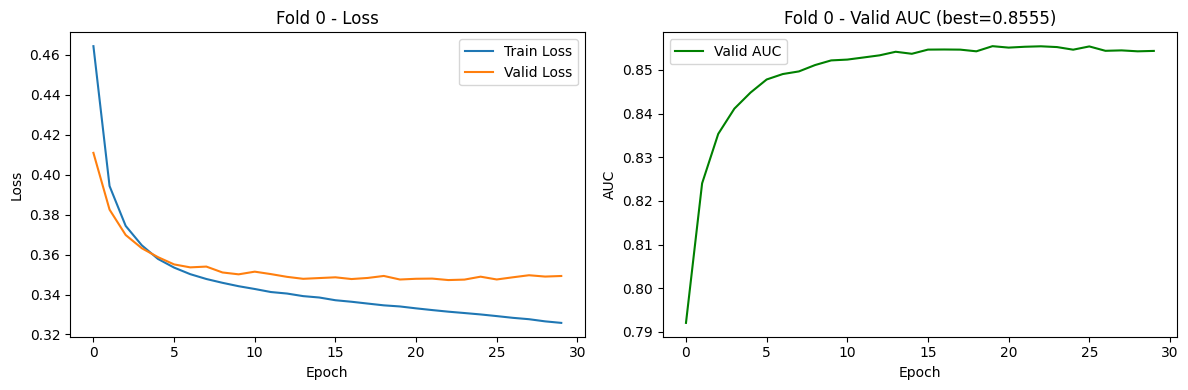

Fold 0 xong. Best valid AUC = 0.8555


In [11]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []       # giữ 5 model đã train xong, ngay trong RAM
all_histories = []        # giữ lịch sử loss/auc từng fold để vẽ biểu đồ
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
for i in range(1):
    print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

    # ---- Chuẩn bị data ----
    train_dataset = DemoDataset(df_train_valid, fold=i, is_train=True)
    valid_dataset = DemoDataset(df_train_valid, fold=i, is_train=False)
    train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

    # ---- Khởi tạo model mới (random init) cho mỗi fold ----
    model = TextFusionIdModel(
        n_questions=config['n_questions'],
        n_concepts=config['n_concepts'],
        embed_dim_id=config['embed_dim_id'],
        embed_dim_text=config['embed_dim_text'],
        matrix_embed_question=matrix_embed_question,
        matrix_embed_concept=matrix_embed_concept,
        hidden_dim=config['hidden_dim'],
        proj_dim=config['proj_dim'],
        top_k=config['top_k']
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=config.get('lr', 1e-3))
    
    # ---- Train fold này ----
    model, history = train_epoch(
        model, train_loader, valid_loader, optimizer, device,
        num_epochs=config.get('num_epochs', 50),
        patience=config.get('patience', 5)
    )

    trained_models.append(model)     # lưu model (đã load best checkpoint) vào RAM
    all_histories.append(history)

    # ---- Vẽ biểu đồ cho fold này ----
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["valid_loss"], label="Valid Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Fold {i} - Loss")
    axes[0].legend()

    axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
    axes[1].legend()

    plt.tight_layout()
    plt.show()          # hiển thị trực tiếp trong Kaggle notebook, không cần lưu file

    print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")

In [12]:
test_dataset = DemoDataset(df_test, fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

test_results = []

for i, model in enumerate(trained_models):
    metrics = evaluate(model, test_loader, device, question_level=True)  # bật True nếu df_test có cột qidxs
    metrics["fold"] = i
    test_results.append(metrics)
    print(f"Fold {i} - Test: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items() if k != "fold"))

Fold 0 - Test: auc=0.8117, acc=0.8257, rmse=0.3538, mae=0.2402, f1=0.8978, precision=0.8409, recall=0.9631


In [13]:
import numpy as np

metric_names = ["auc", "acc", "rmse", "mae", "f1", "precision", "recall"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")


TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.8117 ± 0.0000
ACC       : 0.8257 ± 0.0000
RMSE      : 0.3538 ± 0.0000
MAE       : 0.2402 ± 0.0000
F1        : 0.8978 ± 0.0000
PRECISION : 0.8409 ± 0.0000
RECALL    : 0.9631 ± 0.0000


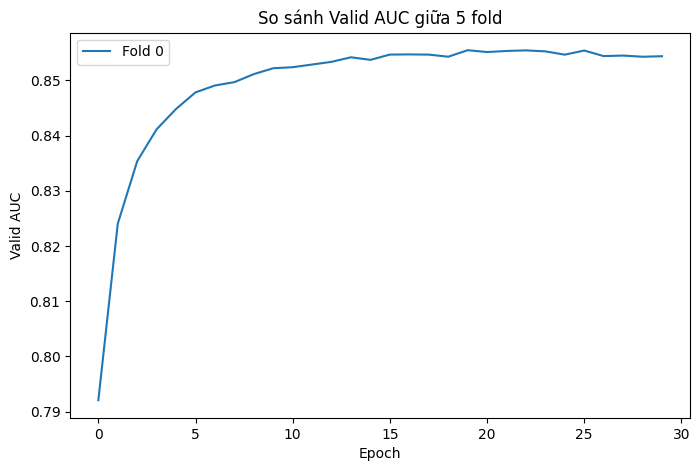

In [14]:
plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()